# 02. Train / validation / test split

In [1]:
from pathlib import Path
import pandas as pd

PROJECT_DIR = Path.cwd().parent
DATA_DIR = PROJECT_DIR / "data" / "processed" / "grid"

labels = pd.read_csv(DATA_DIR / "labels.csv")

print("Rows:", len(labels))
print(labels.head())

Rows: 3960
  speaker    name                   sentence
0      s1  bbaf2n      bin blue at f two now
1      s1  bbaf3s   bin blue at f three soon
2      s1  bbaf4p  bin blue at f four please
3      s1  bbaf5a   bin blue at f five again
4      s1  bbal6n      bin blue at l six now


In [2]:
TEST_SPEAKER = "s4"
VAL_FRACTION = 0.1

labels["split"] = "train"

is_test = labels["speaker"] == TEST_SPEAKER
labels.loc[is_test, "split"] = "test"

train_rows = labels[labels["split"] == "train"]
val_rows = train_rows.sample(frac=VAL_FRACTION, random_state=42)
labels.loc[val_rows.index, "split"] = "val"

In [3]:
print(labels["split"].value_counts())
print()
print(labels.groupby("split")["speaker"].unique())

labels.to_csv(DATA_DIR / "labels_split.csv", index=False)

split
train    2670
test      993
val       297
Name: count, dtype: int64

split
test             [s4]
train    [s1, s2, s3]
val      [s1, s2, s3]
Name: speaker, dtype: object


# 03. Baseline: word classification

In [4]:
from pathlib import Path
import numpy as np
import pandas as pd

PROJECT_DIR = Path.cwd().parent
DATA_DIR = PROJECT_DIR / "data" / "processed" / "grid"
ALIGN_DIR = PROJECT_DIR / "data" / "raw" / "grid" / "alignments"

labels = pd.read_csv(DATA_DIR / "labels_split.csv")

print("Rows:", len(labels))
print(labels["split"].value_counts())

Rows: 3960
split
train    2670
test      993
val       297
Name: count, dtype: int64


In [5]:
SKIP_WORDS = ["sil", "sp"]


def read_words_with_frames(path):
    text = path.read_text()
    lines = text.splitlines()

    words = []
    for line in lines:
        parts = line.split()
        start = int(parts[0])
        end = int(parts[1])
        word = parts[2]

        if word in SKIP_WORDS:
            continue

        start_frame = start // 1000
        end_frame = end // 1000

        words.append((word, start_frame, end_frame))

    return words


test_path = ALIGN_DIR / "s1" / "bbaf2n.align"
for item in read_words_with_frames(test_path):
    print(item)

('bin', 23, 29)
('blue', 29, 34)
('at', 34, 35)
('f', 35, 41)
('two', 41, 47)
('now', 47, 53)


# Word features

In [6]:
import cv2

NUM_FRAMES = 5
SMALL_WIDTH = 20
SMALL_HEIGHT = 10


def word_features(video_array, start_frame, end_frame):
    if end_frame <= start_frame:
        end_frame = start_frame + 1

    clip = video_array[start_frame:end_frame]

    positions = np.linspace(0, len(clip) - 1, NUM_FRAMES)

    small_frames = []
    for position in positions:
        frame_index = int(round(position))
        frame = clip[frame_index]
        small = cv2.resize(frame, (SMALL_WIDTH, SMALL_HEIGHT))
        small_frames.append(small)

    features = np.array(small_frames).flatten() / 255.0
    return features

In [7]:
video_array = np.load(DATA_DIR / "s1" / "bbaf2n.npy")
words = read_words_with_frames(test_path)

for word, start_frame, end_frame in words:
    features = word_features(video_array, start_frame, end_frame)
    print(word, features.shape)

bin (1000,)
blue (1000,)
at (1000,)
f (1000,)
two (1000,)
now (1000,)


## 4. Build datasets

In [8]:
def build_dataset(split_name):
    rows = labels[labels["split"] == split_name]

    X = []
    y = []

    for _, row in rows.iterrows():
        speaker = row["speaker"]
        name = row["name"]

        video_array = np.load(DATA_DIR / speaker / (name + ".npy"))
        align_path = ALIGN_DIR / speaker / (name + ".align")

        for word, start_frame, end_frame in read_words_with_frames(align_path):
            features = word_features(video_array, start_frame, end_frame)
            X.append(features)
            y.append(word)

    return np.array(X), np.array(y)


X_train, y_train = build_dataset("train")
X_val, y_val = build_dataset("val")
X_test, y_test = build_dataset("test")

print("Train:", X_train.shape)
print("Val:", X_val.shape)
print("Test:", X_test.shape)

Train: (16020, 1000)
Val: (1782, 1000)
Test: (5958, 1000)


knn

In [9]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score

knn = KNeighborsClassifier(n_neighbors=5)
knn.fit(X_train, y_train)

val_accuracy = accuracy_score(y_val, knn.predict(X_val))
print("kNN (k=5) val accuracy:", round(val_accuracy, 3))

kNN (k=5) val accuracy: 0.713


In [10]:
val_predictions = knn.predict(X_val)

comparison = pd.DataFrame({
    "true": y_val,
    "predicted": val_predictions,
})
comparison["correct"] = comparison["true"] == comparison["predicted"]

print(comparison.head(12))
print()
print("Correct:", comparison["correct"].sum(), "of", len(comparison))

     true predicted  correct
0     bin       bin     True
1    blue      blue     True
2      at        at     True
3       f       now    False
4     two      soon    False
5     now       now     True
6     bin       bin     True
7    blue      blue     True
8      in        in     True
9       e        at    False
10  eight     eight     True
11    now       now     True

Correct: 1271 of 1782


### 6. Tune kNN

In [11]:
k_values = [1, 3, 5, 7, 9, 15, 25]
weight_options = ["uniform", "distance"]

tuning_rows = []

for weights in weight_options:
    for k in k_values:
        model = KNeighborsClassifier(n_neighbors=k, weights=weights)
        model.fit(X_train, y_train)

        accuracy = accuracy_score(y_val, model.predict(X_val))

        row = {"k": k, "weights": weights, "val_accuracy": round(accuracy, 3)}
        tuning_rows.append(row)

        print(weights, "k =", k, "->", round(accuracy, 3))

tuning = pd.DataFrame(tuning_rows)

best_row = tuning.loc[tuning["val_accuracy"].idxmax()]
best_k = int(best_row["k"])
best_weights = best_row["weights"]

print()
print("Best:", best_weights, "k =", best_k, "->", best_row["val_accuracy"])

uniform k = 1 -> 0.709
uniform k = 3 -> 0.708
uniform k = 5 -> 0.713
uniform k = 7 -> 0.72
uniform k = 9 -> 0.716
uniform k = 15 -> 0.713
uniform k = 25 -> 0.696
distance k = 1 -> 0.709
distance k = 3 -> 0.724
distance k = 5 -> 0.735
distance k = 7 -> 0.736
distance k = 9 -> 0.737
distance k = 15 -> 0.728
distance k = 25 -> 0.71

Best: distance k = 9 -> 0.737


In [12]:
import joblib

final_knn = KNeighborsClassifier(n_neighbors=best_k, weights=best_weights)
final_knn.fit(X_train, y_train)

final_val_accuracy = accuracy_score(y_val, final_knn.predict(X_val))
final_test_accuracy = accuracy_score(y_test, final_knn.predict(X_test))

print("Final kNN:", best_weights, "k =", best_k)
print("Val accuracy:", round(final_val_accuracy, 3))
print("Test accuracy:", round(final_test_accuracy, 3))

MODELS_DIR = PROJECT_DIR / "models"
MODELS_DIR.mkdir(exist_ok=True)
joblib.dump(final_knn, MODELS_DIR / "knn_baseline.joblib")

results = pd.DataFrame([{
    "model": "knn",
    "k": best_k,
    "weights": best_weights,
    "val_accuracy": round(final_val_accuracy, 3),
    "test_accuracy": round(final_test_accuracy, 3),
}])
results.to_csv(DATA_DIR / "baseline_results.csv", index=False)
print(results)

Final kNN: distance k = 9
Val accuracy: 0.737
Test accuracy: 0.122
  model  k   weights  val_accuracy  test_accuracy
0   knn  9  distance         0.737          0.122


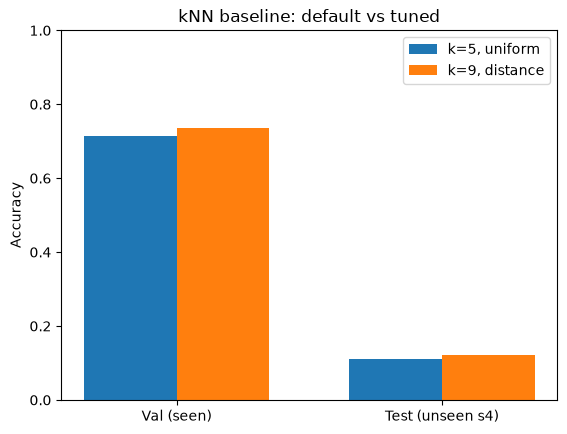

In [13]:
import matplotlib.pyplot as plt

labels_x = ["Val (seen)", "Test (unseen s4)"]
default_scores = [0.713, 0.110]
tuned_scores = [final_val_accuracy, final_test_accuracy]

positions = np.arange(len(labels_x))
bar_width = 0.35

plt.bar(positions - bar_width / 2, default_scores, bar_width, label="k=5, uniform")
plt.bar(positions + bar_width / 2, tuned_scores, bar_width, label="k=9, distance")

plt.xticks(positions, labels_x)
plt.ylabel("Accuracy")
plt.ylim(0, 1)
plt.title("kNN baseline: default vs tuned")
plt.legend()

plt.savefig(PROJECT_DIR / "images" / "knn_baseline.png", dpi=150, bbox_inches="tight")
plt.show()

## 8. Feature experiments


In [14]:
def mean_face_features(video_array, start_frame, end_frame):
    mean_frame = video_array.mean(axis=0)
    centered = video_array - mean_frame
    return word_features(centered, start_frame, end_frame)


def motion_features(video_array, start_frame, end_frame):
    features = word_features(video_array, start_frame, end_frame)
    frames = features.reshape(NUM_FRAMES, SMALL_HEIGHT, SMALL_WIDTH)
    differences = np.diff(frames, axis=0)
    return differences.flatten()

In [15]:
def build_dataset(split_name, feature_function):
    rows = labels[labels["split"] == split_name]

    X = []
    y = []

    for _, row in rows.iterrows():
        speaker = row["speaker"]
        name = row["name"]

        video_array = np.load(DATA_DIR / speaker / (name + ".npy"))
        align_path = ALIGN_DIR / speaker / (name + ".align")

        for word, start_frame, end_frame in read_words_with_frames(align_path):
            features = feature_function(video_array, start_frame, end_frame)
            X.append(features)
            y.append(word)

    return np.array(X), np.array(y)

In [16]:
experiments = {
    "pixels": word_features,
    "mean_face": mean_face_features,
    "motion": motion_features,
}

experiment_rows = []

for name, feature_function in experiments.items():
    X_train_exp, y_train_exp = build_dataset("train", feature_function)
    X_val_exp, y_val_exp = build_dataset("val", feature_function)
    X_test_exp, y_test_exp = build_dataset("test", feature_function)

    model = KNeighborsClassifier(n_neighbors=best_k, weights=best_weights)
    model.fit(X_train_exp, y_train_exp)

    val_acc = accuracy_score(y_val_exp, model.predict(X_val_exp))
    test_acc = accuracy_score(y_test_exp, model.predict(X_test_exp))

    experiment_rows.append({
        "features": name,
        "val_accuracy": round(val_acc, 3),
        "test_accuracy": round(test_acc, 3),
    })
    print(name, "done")

experiment_results = pd.DataFrame(experiment_rows)
experiment_results.to_csv(DATA_DIR / "feature_experiments.csv", index=False)
print(experiment_results)

pixels done
mean_face done
motion done
    features  val_accuracy  test_accuracy
0     pixels         0.737          0.122
1  mean_face         0.782          0.177
2     motion         0.631          0.049


## 1. Setup and GPU

In [17]:
import torch

PROJECT_DIR = Path.cwd().parent
DATA_DIR = PROJECT_DIR / "data" / "processed" / "grid"

labels = pd.read_csv(DATA_DIR / "labels_split.csv")
print("Rows:", len(labels))

print("GPU available:", torch.cuda.is_available())
if torch.cuda.is_available():
    print("GPU name:", torch.cuda.get_device_name(0))

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using:", device)

Rows: 3960
GPU available: True
GPU name: NVIDIA GeForce RTX 4060 Ti
Using: cuda


In [18]:
import string

BLANK = "_"
CHARACTERS = [BLANK] + list(string.ascii_lowercase) + [" "]

char_to_index = {}
for index, char in enumerate(CHARACTERS):
    char_to_index[char] = index


def text_to_numbers(text):
    numbers = []
    for char in text:
        numbers.append(char_to_index[char])
    return numbers


def numbers_to_text(numbers):
    chars = []
    for number in numbers:
        chars.append(CHARACTERS[number])
    return "".join(chars)


print("Number of symbols:", len(CHARACTERS))
example = "bin blue"
encoded = text_to_numbers(example)
print(example, "->", encoded)
print(encoded, "->", numbers_to_text(encoded))

Number of symbols: 28
bin blue -> [2, 9, 14, 27, 2, 12, 21, 5]
[2, 9, 14, 27, 2, 12, 21, 5] -> bin blue


In [19]:
from torch.utils.data import Dataset


class GridDataset(Dataset):
    def __init__(self, table):
        self.table = table.reset_index(drop=True)

    def __len__(self):
        return len(self.table)

    def __getitem__(self, index):
        row = self.table.iloc[index]

        video_path = DATA_DIR / row["speaker"] / (row["name"] + ".npy")
        video = np.load(video_path).astype(np.float32)

        video = (video - video.mean()) / (video.std() + 1e-6)
        video = video[np.newaxis]

        label = text_to_numbers(row["sentence"])

        video_tensor = torch.tensor(video)
        label_tensor = torch.tensor(label, dtype=torch.long)
        return video_tensor, label_tensor


train_dataset = GridDataset(labels[labels["split"] == "train"])

video, label = train_dataset[0]
print("Train size:", len(train_dataset))
print("Video shape:", video.shape)
print("Label:", label.tolist())
print("Label as text:", numbers_to_text(label.tolist()))

Train size: 2670
Video shape: torch.Size([1, 75, 40, 80])
Label: [2, 9, 14, 27, 2, 12, 21, 5, 27, 1, 20, 27, 6, 27, 20, 8, 18, 5, 5, 27, 19, 15, 15, 14]
Label as text: bin blue at f three soon


## 4. DataLoader

In [20]:
from torch.utils.data import DataLoader
from torch.nn.utils.rnn import pad_sequence

BATCH_SIZE = 16


def collate_batch(batch):
    videos = []
    label_list = []
    label_lengths = []

    for video, label in batch:
        videos.append(video)
        label_list.append(label)
        label_lengths.append(len(label))

    videos = torch.stack(videos)
    padded_labels = pad_sequence(label_list, batch_first=True, padding_value=0)
    label_lengths = torch.tensor(label_lengths, dtype=torch.long)

    return videos, padded_labels, label_lengths


val_dataset = GridDataset(labels[labels["split"] == "val"])
test_dataset = GridDataset(labels[labels["split"] == "test"])

train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True, collate_fn=collate_batch)
val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False, collate_fn=collate_batch)
test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False, collate_fn=collate_batch)

videos, padded_labels, label_lengths = next(iter(train_loader))
print("Videos:", videos.shape)
print("Labels:", padded_labels.shape)
print("Label lengths:", label_lengths.tolist())

Videos: torch.Size([16, 1, 75, 40, 80])
Labels: torch.Size([16, 27])
Label lengths: [26, 26, 25, 23, 24, 27, 26, 22, 23, 26, 24, 25, 26, 27, 26, 27]


## 5. Model

In [21]:
import torch.nn as nn

NUM_CLASSES = len(CHARACTERS)


class LipReadingModel(nn.Module):
    def __init__(self):
        super().__init__()

        self.conv_block1 = nn.Sequential(
            nn.Conv3d(1, 32, kernel_size=(3, 5, 5), padding=(1, 2, 2)),
            nn.ReLU(),
            nn.MaxPool3d(kernel_size=(1, 2, 2)),
            nn.Dropout3d(0.3),
        )

        self.conv_block2 = nn.Sequential(
            nn.Conv3d(32, 64, kernel_size=(3, 5, 5), padding=(1, 2, 2)),
            nn.ReLU(),
            nn.MaxPool3d(kernel_size=(1, 2, 2)),
            nn.Dropout3d(0.3),
        )

        self.conv_block3 = nn.Sequential(
            nn.Conv3d(64, 96, kernel_size=(3, 3, 3), padding=(1, 1, 1)),
            nn.ReLU(),
            nn.MaxPool3d(kernel_size=(1, 2, 2)),
            nn.Dropout3d(0.3),
        )

        self.gru = nn.GRU(
            input_size=96 * 5 * 10,
            hidden_size=256,
            num_layers=2,
            batch_first=True,
            bidirectional=True,
            dropout=0.3,
        )

        self.classifier = nn.Linear(256 * 2, NUM_CLASSES)

    def forward(self, videos):
        x = self.conv_block1(videos)
        x = self.conv_block2(x)
        x = self.conv_block3(x)

        x = x.permute(0, 2, 1, 3, 4)
        batch_size = x.shape[0]
        num_frames = x.shape[1]
        x = x.reshape(batch_size, num_frames, -1)

        x, _ = self.gru(x)
        x = self.classifier(x)

        return x.log_softmax(dim=2)

In [22]:
model = LipReadingModel().to(device)

num_parameters = sum(p.numel() for p in model.parameters())
print("Parameters:", num_parameters)

videos = videos.to(device)
outputs = model(videos)
print("Output shape:", outputs.shape)

Parameters: 9288252
Output shape: torch.Size([16, 75, 28])


## 6. Loss and sanity check

In [23]:
ctc_loss = nn.CTCLoss(blank=0, zero_infinity=True)


def compute_loss(model, videos, padded_labels, label_lengths):
    videos = videos.to(device)
    padded_labels = padded_labels.to(device)
    label_lengths = label_lengths.to(device)

    outputs = model(videos)
    outputs = outputs.permute(1, 0, 2)

    num_frames = outputs.shape[0]
    batch_size = outputs.shape[1]
    input_lengths = torch.full((batch_size,), num_frames, dtype=torch.long, device=device)

    loss = ctc_loss(outputs, padded_labels, input_lengths, label_lengths)
    return loss

In [24]:
optimizer = torch.optim.Adam(model.parameters(), lr=1e-4)

model.train()

for step in range(30):
    optimizer.zero_grad()

    loss = compute_loss(model, videos, padded_labels, label_lengths)

    loss.backward()
    optimizer.step()

    if step % 5 == 0:
        print("Step", step, "loss:", round(loss.item(), 3))

Step 0 loss: 7.433
Step 5 loss: 3.513
Step 10 loss: 3.254
Step 15 loss: 2.912
Step 20 loss: 2.922
Step 25 loss: 2.832


In [25]:
def greedy_decode(outputs):
    best_numbers = outputs.argmax(dim=2)

    texts = []
    for sequence in best_numbers:
        chars = []
        previous = None

        for number in sequence.tolist():
            if number != previous and number != 0:
                chars.append(CHARACTERS[number])
            previous = number

        texts.append("".join(chars))

    return texts


def evaluate(model, loader):
    model.eval()

    total_loss = 0
    predictions = []
    targets = []

    with torch.no_grad():
        for videos, padded_labels, label_lengths in loader:
            videos = videos.to(device)
            padded_labels = padded_labels.to(device)
            label_lengths = label_lengths.to(device)

            outputs = model(videos)

            log_probs = outputs.permute(1, 0, 2)
            input_lengths = torch.full((videos.shape[0],), log_probs.shape[0], dtype=torch.long, device=device)
            loss = ctc_loss(log_probs, padded_labels, input_lengths, label_lengths)
            total_loss += loss.item()

            predictions.extend(greedy_decode(outputs))

            for label, length in zip(padded_labels, label_lengths):
                targets.append(numbers_to_text(label[:length].tolist()))

    model.train()
    average_loss = total_loss / len(loader)
    return average_loss, predictions, targets

## 8. Training

In [26]:
from tqdm import tqdm

NUM_EPOCHS = 30
MODELS_DIR = PROJECT_DIR / "models"
MODELS_DIR.mkdir(exist_ok=True)

model = LipReadingModel().to(device)
optimizer = torch.optim.Adam(model.parameters(), lr=1e-4)

best_val_loss = float("inf")
history = []

for epoch in range(NUM_EPOCHS):
    model.train()
    train_loss_sum = 0

    for videos, padded_labels, label_lengths in tqdm(train_loader, desc="Epoch " + str(epoch + 1)):
        optimizer.zero_grad()
        loss = compute_loss(model, videos, padded_labels, label_lengths)
        loss.backward()
        optimizer.step()
        train_loss_sum += loss.item()

    train_loss = train_loss_sum / len(train_loader)
    val_loss, predictions, targets = evaluate(model, val_loader)

    history.append({"epoch": epoch + 1, "train_loss": train_loss, "val_loss": val_loss})
    print("Epoch", epoch + 1, "train loss:", round(train_loss, 3), "val loss:", round(val_loss, 3))

    for i in range(2):
        print("   true:", targets[i])
        print("   pred:", predictions[i])

    if val_loss < best_val_loss:
        best_val_loss = val_loss
        torch.save(model.state_dict(), MODELS_DIR / "lipnet_best.pt")
        print("   saved best model")

Epoch 1: 100%|██████████| 167/167 [00:39<00:00,  4.19it/s]


Epoch 1 train loss: 2.871 val loss: 2.645
   true: bin blue at f two now
   pred: n
   true: bin blue in e eight now
   pred: n
   saved best model


Epoch 2: 100%|██████████| 167/167 [00:41<00:00,  4.03it/s]


Epoch 2 train loss: 2.567 val loss: 2.5
   true: bin blue at f two now
   pred: laon
   true: bin blue in e eight now
   pred: lon
   saved best model


Epoch 3:  38%|███▊      | 63/167 [00:15<00:25,  4.05it/s]


KeyboardInterrupt: 

## 9. Metrics

In [ ]:
import jiwer


def compute_metrics(predictions, targets):
    wer = jiwer.wer(targets, predictions)
    cer = jiwer.cer(targets, predictions)

    correct_words = 0
    total_words = 0

    for prediction, target in zip(predictions, targets):
        predicted_words = prediction.split()
        target_words = target.split()

        for position in range(len(target_words)):
            total_words += 1

            if position < len(predicted_words):
                if predicted_words[position] == target_words[position]:
                    correct_words += 1

    word_accuracy = correct_words / total_words
    return wer, cer, word_accuracy

In [ ]:
model = LipReadingModel().to(device)
model.load_state_dict(torch.load(MODELS_DIR / "lipnet_best.pt"))

val_loss, predictions, targets = evaluate(model, val_loader)
wer, cer, word_accuracy = compute_metrics(predictions, targets)

print("Val loss:", round(val_loss, 3))
print("WER:", round(wer, 3))
print("CER:", round(cer, 3))
print("Word accuracy:", round(word_accuracy, 3))

Val loss: 0.552
WER: 0.469
CER: 0.208
Word accuracy: 0.531


saving

In [ ]:
import shutil

shutil.copy(MODELS_DIR / "lipnet_best.pt", MODELS_DIR / "lipnet_epoch30.pt")


WindowsPath('c:/Users/vova1/Documents/vscodefiles/resume projects/Speech recognition/models/lipnet_epoch30.pt')

In [ ]:
import mlflow

MLFLOW_DB = PROJECT_DIR / "mlflow.db"
mlflow.set_tracking_uri("sqlite:///" + MLFLOW_DB.as_posix())
mlflow.set_experiment("lipnet-grid")

c:\Users\vova1\miniconda3\envs\lip\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
2026/10/20 18:54:45 INFO mlflow.store.db.utils: Creating initial MLflow database tables...
2026/10/20 18:54:45 INFO mlflow.store.db.utils: Updating database tables
2026/10/20 18:54:46 INFO mlflow.tracking.fluent: Experiment with name 'lipnet-grid' does not exist. Creating a new experiment.


<Experiment: artifact_location=('file:///c:/Users/vova1/Documents/vscodefiles/resume projects/Speech '
 'recognition/notebooks/mlruns/1'), creation_time=1792547686773, effective_trace_archival_retention=None, experiment_id='1', last_update_time=1792547686773, lifecycle_stage='active', name='lipnet-grid', tags={}, trace_location=None, workspace='default'>

In [ ]:
import random


class GridDataset(Dataset):
    def __init__(self, table, augment=False):
        self.table = table.reset_index(drop=True)
        self.augment = augment

    def __len__(self):
        return len(self.table)

    def __getitem__(self, index):
        row = self.table.iloc[index]

        video_path = DATA_DIR / row["speaker"] / (row["name"] + ".npy")
        video = np.load(video_path).astype(np.float32)

        if self.augment and random.random() < 0.5:
            video = video[:, :, ::-1].copy()

        video = (video - video.mean()) / (video.std() + 1e-6)
        video = video[np.newaxis]

        label = text_to_numbers(row["sentence"])

        video_tensor = torch.tensor(video)
        label_tensor = torch.tensor(label, dtype=torch.long)
        return video_tensor, label_tensor


def make_train_loader(use_augmentation):
    dataset = GridDataset(labels[labels["split"] == "train"], augment=use_augmentation)
    return DataLoader(dataset, batch_size=BATCH_SIZE, shuffle=True, collate_fn=collate_batch)


val_dataset = GridDataset(labels[labels["split"] == "val"])
val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False, collate_fn=collate_batch)

In [ ]:
def train_run(run_name, use_augmentation, extra_epochs=50, learning_rate=1e-4, patience=8):
    train_loader = make_train_loader(use_augmentation)

    model = LipReadingModel().to(device)
    model.load_state_dict(torch.load(MODELS_DIR / "lipnet_epoch30.pt"))

    optimizer = torch.optim.Adam(model.parameters(), lr=learning_rate)
    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode="min", factor=0.5, patience=3)

    best_val_loss, _, _ = evaluate(model, val_loader)
    epochs_without_improvement = 0
    checkpoint_path = MODELS_DIR / (run_name + ".pt")

    with mlflow.start_run(run_name=run_name):
        mlflow.log_params({
            "start_from": "epoch 30",
            "extra_epochs": extra_epochs,
            "learning_rate": learning_rate,
            "batch_size": BATCH_SIZE,
            "dropout": 0.3,
            "gru_hidden_size": 256,
            "augmentation": use_augmentation,
            "early_stopping_patience": patience,
        })

        for epoch in range(31, 31 + extra_epochs):
            model.train()
            train_loss_sum = 0

            for videos, padded_labels, label_lengths in tqdm(train_loader, desc="Epoch " + str(epoch)):
                optimizer.zero_grad()
                loss = compute_loss(model, videos, padded_labels, label_lengths)
                loss.backward()
                optimizer.step()
                train_loss_sum += loss.item()

            train_loss = train_loss_sum / len(train_loader)
            val_loss, predictions, targets = evaluate(model, val_loader)
            wer, cer, word_accuracy = compute_metrics(predictions, targets)

            scheduler.step(val_loss)
            current_lr = optimizer.param_groups[0]["lr"]

            mlflow.log_metrics({
                "train_loss": train_loss,
                "val_loss": val_loss,
                "val_wer": wer,
                "val_cer": cer,
                "val_word_accuracy": word_accuracy,
                "learning_rate": current_lr,
            }, step=epoch)

            print("Epoch", epoch, "val loss:", round(val_loss, 3), "WER:", round(wer, 3),
                  "word acc:", round(word_accuracy, 3), "lr:", current_lr)
            print("   true:", targets[0])
            print("   pred:", predictions[0])

            if val_loss < best_val_loss:
                best_val_loss = val_loss
                epochs_without_improvement = 0
                checkpoint = {
                    "epoch": epoch,
                    "model": model.state_dict(),
                    "optimizer": optimizer.state_dict(),
                }
                torch.save(checkpoint, checkpoint_path)
                print("   saved best checkpoint")
            else:
                epochs_without_improvement += 1

            if epochs_without_improvement >= patience:
                print("Early stopping: no improvement for", patience, "epochs")
                break

        mlflow.log_metric("best_val_loss", best_val_loss)

    return checkpoint_path

In [ ]:
checkpoint_a = train_run("run_A_no_augmentation", use_augmentation=False)

Epoch 31: 100%|██████████| 167/167 [00:40<00:00,  4.16it/s]


Epoch 31 val loss: 0.501 WER: 0.447 word acc: 0.553 lr: 0.0001
   true: bin blue at f two now
   pred: bin blue it b oo now
   saved best checkpoint


Epoch 32: 100%|██████████| 167/167 [00:40<00:00,  4.12it/s]


Epoch 32 val loss: 0.481 WER: 0.423 word acc: 0.577 lr: 0.0001
   true: bin blue at f two now
   pred: bin blue in b oo now
   saved best checkpoint


Epoch 33: 100%|██████████| 167/167 [00:39<00:00,  4.19it/s]


Epoch 33 val loss: 0.452 WER: 0.412 word acc: 0.588 lr: 0.0001
   true: bin blue at f two now
   pred: bin blue an b oo now
   saved best checkpoint


... (90 outputs left out)

Epoch 79: 100%|██████████| 167/167 [00:40<00:00,  4.12it/s]


Epoch 79 val loss: 0.134 WER: 0.1 word acc: 0.898 lr: 0.0001
   true: bin blue at f two now
   pred: bin blue an b two now


Epoch 80: 100%|██████████| 167/167 [00:40<00:00,  4.13it/s]


Epoch 80 val loss: 0.137 WER: 0.102 word acc: 0.898 lr: 0.0001
   true: bin blue at f two now
   pred: bin blue at b two now


In [ ]:
checkpoint_b = train_run("run_B_flip_augmentation", use_augmentation=True)

Epoch 31: 100%|██████████| 167/167 [00:40<00:00,  4.13it/s]


Epoch 31 val loss: 0.512 WER: 0.447 word acc: 0.553 lr: 0.0001
   true: bin blue at f two now
   pred: bin blue y b oo now
   saved best checkpoint


Epoch 32: 100%|██████████| 167/167 [00:38<00:00,  4.30it/s]


Epoch 32 val loss: 0.504 WER: 0.438 word acc: 0.562 lr: 0.0001
   true: bin blue at f two now
   pred: bin blue y b oo now
   saved best checkpoint


Epoch 33: 100%|██████████| 167/167 [00:38<00:00,  4.29it/s]


Epoch 33 val loss: 0.471 WER: 0.429 word acc: 0.57 lr: 0.0001
   true: bin blue at f two now
   pred: bin blue ay b oo now
   saved best checkpoint


... (90 outputs left out)

Epoch 79: 100%|██████████| 167/167 [00:39<00:00,  4.22it/s]


Epoch 79 val loss: 0.135 WER: 0.102 word acc: 0.898 lr: 0.0001
   true: bin blue at f two now
   pred: bin blue in b two now


Epoch 80: 100%|██████████| 167/167 [00:39<00:00,  4.21it/s]


Epoch 80 val loss: 0.133 WER: 0.1 word acc: 0.9 lr: 0.0001
   true: bin blue at f two now
   pred: bin blue in t two now


## 11. Compare runs A and B

In [ ]:
from pathlib import Path
import matplotlib.pyplot as plt
import mlflow

PROJECT_DIR = Path.cwd().parent

MLFLOW_DB = PROJECT_DIR / "mlflow.db"
mlflow.set_tracking_uri("sqlite:///" + MLFLOW_DB.as_posix())
mlflow.set_experiment("lipnet-grid")
runs = mlflow.search_runs(experiment_names=["lipnet-grid"])

columns = [
    "tags.mlflow.runName",
    "metrics.best_val_loss",
    "metrics.val_word_accuracy",
    "metrics.val_wer",
    "metrics.val_cer",
]
print(runs[columns])

c:\Users\vova1\miniconda3\envs\lip\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


       tags.mlflow.runName  metrics.best_val_loss  metrics.val_word_accuracy  \
0  run_B_flip_augmentation               0.131658                   0.900112   
1    run_A_no_augmentation               0.129743                   0.898429   

   metrics.val_wer  metrics.val_cer  
0         0.099888         0.034258  
1         0.101571         0.035481  


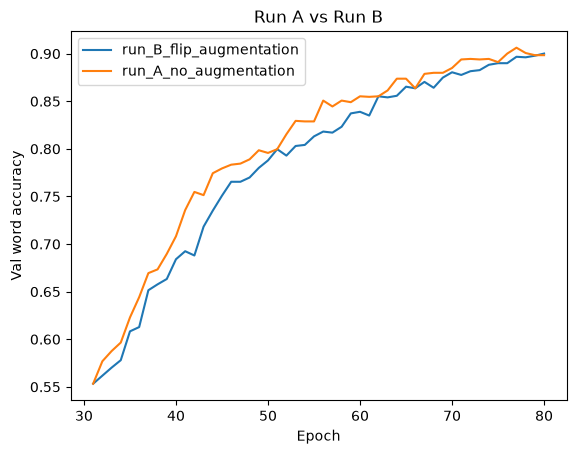

In [ ]:
client = mlflow.tracking.MlflowClient()

for _, run in runs.iterrows():
    history = client.get_metric_history(run["run_id"], "val_word_accuracy")

    epochs = []
    values = []
    for point in history:
        epochs.append(point.step)
        values.append(point.value)

    plt.plot(epochs, values, label=run["tags.mlflow.runName"])

plt.xlabel("Epoch")
plt.ylabel("Val word accuracy")
plt.title("Run A vs Run B")
plt.legend()
plt.savefig(PROJECT_DIR / "images" / "runs_a_vs_b.png", dpi=150, bbox_inches="tight")
plt.show()

## 12. Final test on unseen speaker s4

In [1]:
import sys
from pathlib import Path
import pandas as pd
import torch
from torch.utils.data import DataLoader

PROJECT_DIR = Path.cwd().parent
sys.path.append(str(PROJECT_DIR))

from src.data import GridDataset, collate_batch
from src.model import LipReadingModel
from src.evaluation import evaluate, compute_metrics

DATA_DIR = PROJECT_DIR / "data" / "processed" / "grid"
MODELS_DIR = PROJECT_DIR / "models"
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

labels = pd.read_csv(DATA_DIR / "labels_split.csv")
test_dataset = GridDataset(labels[labels["split"] == "test"], DATA_DIR)
test_loader = DataLoader(test_dataset, batch_size=16, shuffle=False, collate_fn=collate_batch)

In [2]:
checkpoint = torch.load(MODELS_DIR / "run_A_no_augmentation.pt")
print("Best epoch:", checkpoint["epoch"])

model = LipReadingModel().to(device)
model.load_state_dict(checkpoint["model"])

test_loss, test_predictions, test_targets = evaluate(model, test_loader, device)
test_wer, test_cer, test_word_accuracy = compute_metrics(test_predictions, test_targets)

print("Test WER:", round(test_wer, 3))
print("Test CER:", round(test_cer, 3))
print("Test word accuracy:", round(test_word_accuracy, 3))

for i in range(5):
    print("   true:", test_targets[i])
    print("   pred:", test_predictions[i])

Best epoch: 78
Test WER: 0.743
Test CER: 0.517
Test word accuracy: 0.257
   true: bin blue at e nine now
   pred: lay white in s ine now
   true: bin blue at f one please
   pred: lay white iy y nine again
   true: bin blue at f zero soon
   pred: lay white at o oue now
   true: bin blue at l three now
   pred: lay white in h one again
   true: bin blue at l four soon
   pred: slay white in o one again
